In [1]:
install.packages("tidyverse")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [3]:
install.packages(c("nycflights13", "gapminder", "Lahman"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



# Hoofdstuk 3 - Data Transformation with dplyr

We gaan een aantal technieken oefenen waarmee je data kunt manipuleren:<br>
- filteren = filter<br>
- herordenen = arrange<br>
- selecteren = select<br>
- wijzigen = mutate<br>
- samenvatten = summarize or group by<br>

<p>
De dataset waarmee we deze oefeningen doen, is de nycflights13:<br>
een dataset met gegevens over alle vluchten die in 2013 zijn vertrokken vanuit New York City.

In [30]:
??nycflights13

Omdat we R-code draaien in een Python-omgeving, moeten we bij het verwijzen naar de dataset opletten dat de Python-omgeving de dataset herkend als een dataframe (tibble): nycflights::flights

In [11]:
nycflights13::flights

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
2013,1,1,544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
2013,1,1,554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
2013,1,1,554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
2013,1,1,555,600,-5,913,854,19,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00


# 5.2 Filteren
We gaan filteren:

In [13]:
filter(nycflights13::flights, month == 1, day == 1)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
2013,1,1,544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
2013,1,1,554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
2013,1,1,554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
2013,1,1,555,600,-5,913,854,19,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00


Het resultaat van het filter opslaan in een variabele:

In [14]:
jan1 <- filter(nycflights13::flights, month == 1, day == 1)

Printen en opslaan in 1x:

In [15]:
(dec25 <- filter(nycflights13::flights, month == 12, day == 25))

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,12,25,456,500,-4,649,651,-2,US,1895,N156UW,EWR,CLT,98,529,5,0,2013-12-25 05:00:00
2013,12,25,524,515,9,805,814,-9,UA,1016,N32404,EWR,IAH,203,1400,5,15,2013-12-25 05:00:00
2013,12,25,542,540,2,832,850,-18,AA,2243,N5EBAA,JFK,MIA,146,1089,5,40,2013-12-25 05:00:00
2013,12,25,546,550,-4,1022,1027,-5,B6,939,N665JB,JFK,BQN,191,1576,5,50,2013-12-25 05:00:00
2013,12,25,556,600,-4,730,745,-15,AA,301,N3JLAA,LGA,ORD,123,733,6,0,2013-12-25 06:00:00
2013,12,25,557,600,-3,743,752,-9,DL,731,N369NB,LGA,DTW,88,502,6,0,2013-12-25 06:00:00
2013,12,25,557,600,-3,818,831,-13,DL,904,N397DA,LGA,ATL,118,762,6,0,2013-12-25 06:00:00
2013,12,25,559,600,-1,855,856,-1,B6,371,N608JB,LGA,FLL,147,1076,6,0,2013-12-25 06:00:00
2013,12,25,559,600,-1,849,855,-6,B6,605,N536JB,EWR,FLL,149,1065,6,0,2013-12-25 06:00:00


Filteren met de 'logical operators' | = OR en & = AND:

In [16]:
filter(nycflights13::flights, month == 11 | month == 12)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,11,1,5,2359,6,352,345,7,B6,745,N568JB,JFK,PSE,205,1617,23,59,2013-11-01 23:00:00
2013,11,1,35,2250,105,123,2356,87,B6,1816,N353JB,JFK,SYR,36,209,22,50,2013-11-01 22:00:00
2013,11,1,455,500,-5,641,651,-10,US,1895,N192UW,EWR,CLT,88,529,5,0,2013-11-01 05:00:00
2013,11,1,539,545,-6,856,827,29,UA,1714,N38727,LGA,IAH,229,1416,5,45,2013-11-01 05:00:00
2013,11,1,542,545,-3,831,855,-24,AA,2243,N5CLAA,JFK,MIA,147,1089,5,45,2013-11-01 05:00:00
2013,11,1,549,600,-11,912,923,-11,UA,303,N595UA,JFK,SFO,359,2586,6,0,2013-11-01 06:00:00
2013,11,1,550,600,-10,705,659,6,US,2167,N748UW,LGA,DCA,57,214,6,0,2013-11-01 06:00:00
2013,11,1,554,600,-6,659,701,-2,US,2134,N742PS,LGA,BOS,40,184,6,0,2013-11-01 06:00:00
2013,11,1,554,600,-6,826,827,-1,DL,563,N912DE,LGA,ATL,126,762,6,0,2013-11-01 06:00:00


In [17]:
nov_dec <- filter(nycflights13::flights, month %in% c(11, 12))

Filteren is ook handig om NA-waarden te vinden:

In [20]:
df <- tibble(x = c(1, NA, 3))
df

x
<dbl>
1
NA
3


In [21]:
filter(df, x > 1)

x
<dbl>
3


In [19]:
filter(df, is.na(x) | x > 1)

x
<dbl>
NA
3


# 5.3 Ordenen

We ordenen (= op volgorde zetten) de data eerst op basis van jaar, dan maand, dan dag:

In [22]:
arrange(nycflights13::flights, year, month, day)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
2013,1,1,544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
2013,1,1,554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
2013,1,1,554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
2013,1,1,555,600,-5,913,854,19,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00


In 'descending' = aflopende volgorde = hoogste eerst. In dit voorbeeld: als eerste de vluchten met de grootste vertraging.

In [23]:
arrange(nycflights13::flights, desc(dep_delay))

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,9,641,900,1301,1242,1530,1272,HA,51,N384HA,JFK,HNL,640,4983,9,0,2013-01-09 09:00:00
2013,6,15,1432,1935,1137,1607,2120,1127,MQ,3535,N504MQ,JFK,CMH,74,483,19,35,2013-06-15 19:00:00
2013,1,10,1121,1635,1126,1239,1810,1109,MQ,3695,N517MQ,EWR,ORD,111,719,16,35,2013-01-10 16:00:00
2013,9,20,1139,1845,1014,1457,2210,1007,AA,177,N338AA,JFK,SFO,354,2586,18,45,2013-09-20 18:00:00
2013,7,22,845,1600,1005,1044,1815,989,MQ,3075,N665MQ,JFK,CVG,96,589,16,0,2013-07-22 16:00:00
2013,4,10,1100,1900,960,1342,2211,931,DL,2391,N959DL,JFK,TPA,139,1005,19,0,2013-04-10 19:00:00
2013,3,17,2321,810,911,135,1020,915,DL,2119,N927DA,LGA,MSP,167,1020,8,10,2013-03-17 08:00:00
2013,6,27,959,1900,899,1236,2226,850,DL,2007,N3762Y,JFK,PDX,313,2454,19,0,2013-06-27 19:00:00
2013,7,22,2257,759,898,121,1026,895,DL,2047,N6716C,LGA,ATL,109,762,7,59,2013-07-22 07:00:00


# 5.4 Select
Selecteer alleen die kolommen uit je dataset die je ook wilt gebruiken:

In [ ]:
# Select columns by name
select(nycflights13::flights, year, month, day)

year,month,day
<int>,<int>,<int>
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1


In [ ]:
# Select all columns between year and day (inclusive)
select(nycflights13::flights, year:day)

year,month,day
<int>,<int>,<int>
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1
2013,1,1


In [ ]:
# Select all columns except those from year to day (inclusive)
select(nycflights13::flights, -(year:day))

dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
555,600,-5,913,854,19,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00
557,600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00
557,600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00


Gebruik rename als je kolommen wilt hernoemen:

In [ ]:
rename(nycflights13::flights, tail_num = tailnum)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tail_num,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
2013,1,1,544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
2013,1,1,554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00
2013,1,1,554,558,-4,740,728,12,UA,1696,N39463,EWR,ORD,150,719,5,58,2013-01-01 05:00:00
2013,1,1,555,600,-5,913,854,19,B6,507,N516JB,EWR,FLL,158,1065,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,709,723,-14,EV,5708,N829AS,LGA,IAD,53,229,6,0,2013-01-01 06:00:00
2013,1,1,557,600,-3,838,846,-8,B6,79,N593JB,JFK,MCO,140,944,6,0,2013-01-01 06:00:00


Zie ?select voor meer mogelijkheden met het Select-commando.

# 5.5 Mutate
Altijd handig als we een nieuwe variabele als kolom aan (het eind van) onze dataset kunnen toevoegen. We gaan dit oefenen met een iets kleinere versie van onze originele dataset:

In [ ]:
flights_sml <- select(nycflights13::flights,
  year:day,
  ends_with("delay"),
  distance,
  air_time
)

In [ ]:
flights_sml

year,month,day,dep_delay,arr_delay,distance,air_time
<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
2013,1,1,2,11,1400,227
2013,1,1,4,20,1416,227
2013,1,1,2,33,1089,160
2013,1,1,-1,-18,1576,183
2013,1,1,-6,-25,762,116
2013,1,1,-4,12,719,150
2013,1,1,-5,19,1065,158
2013,1,1,-3,-14,229,53
2013,1,1,-3,-8,944,140


Aan deze dataset gaan we twee kolommen toevoegen:<br>
- hoeveel het vliegtuig tijdens de vlucht is ingelopen op de vertraging bij de start ('gain')<br>
- hoe snel het vliegtuig gevlogen heeft ('speed')

In [ ]:
mutate(flights_sml,
  gain = dep_delay - arr_delay,
  speed = distance / air_time * 60
)

year,month,day,dep_delay,arr_delay,distance,air_time,gain,speed
<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2013,1,1,2,11,1400,227,-9,370.0441
2013,1,1,4,20,1416,227,-16,374.2731
2013,1,1,2,33,1089,160,-31,408.3750
2013,1,1,-1,-18,1576,183,17,516.7213
2013,1,1,-6,-25,762,116,19,394.1379
2013,1,1,-4,12,719,150,-16,287.6000
2013,1,1,-5,19,1065,158,-24,404.4304
2013,1,1,-3,-14,229,53,11,259.2453
2013,1,1,-3,-8,944,140,5,404.5714


Ook aan de nieuwe dataset kun je weer kolommen toevoegen:

In [ ]:
mutate(flights_sml,
  gain = dep_delay - arr_delay,
  hours = air_time / 60,
  gain_per_hour = gain / hours
)

year,month,day,dep_delay,arr_delay,distance,air_time,gain,hours,gain_per_hour
<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2013,1,1,2,11,1400,227,-9,3.7833333,-2.3788546
2013,1,1,4,20,1416,227,-16,3.7833333,-4.2290749
2013,1,1,2,33,1089,160,-31,2.6666667,-11.6250000
2013,1,1,-1,-18,1576,183,17,3.0500000,5.5737705
2013,1,1,-6,-25,762,116,19,1.9333333,9.8275862
2013,1,1,-4,12,719,150,-16,2.5000000,-6.4000000
2013,1,1,-5,19,1065,158,-24,2.6333333,-9.1139241
2013,1,1,-3,-14,229,53,11,0.8833333,12.4528302
2013,1,1,-3,-8,944,140,5,2.3333333,2.1428571


Met transmute houd je alleen de nieuwe kolommen over:

In [ ]:
transmute(nycflights13::flights,
  gain = dep_delay - arr_delay,
  hours = air_time / 60,
  gain_per_hour = gain / hours
)

gain,hours,gain_per_hour
<dbl>,<dbl>,<dbl>
-9,3.7833333,-2.3788546
-16,3.7833333,-4.2290749
-31,2.6666667,-11.6250000
17,3.0500000,5.5737705
19,1.9333333,9.8275862
-16,2.5000000,-6.4000000
-24,2.6333333,-9.1139241
11,0.8833333,12.4528302
5,2.3333333,2.1428571


Je kunt met transmute ook tijden omrekenen naar uren en minuten:

In [ ]:
transmute(nycflights13::flights,
  dep_time,
  hour = dep_time %/% 100,
  minute = dep_time %% 100
)

dep_time,hour,minute
<int>,<dbl>,<dbl>
517,5,17
533,5,33
542,5,42
544,5,44
554,5,54
554,5,54
555,5,55
557,5,57
557,5,57


# 5.5 Summarise & Group By
Even samenvatten:

In [ ]:
summarise(nycflights13::flights, delay = mean(dep_delay, na.rm = TRUE)) # na.rm verwijdert eerst de NA's zodat het gemiddelde berekend kan worden

delay
<dbl>
12.63907


Mooier is de summarise te combineren met een group by, zodat je per groep een resultaat krijgt. Bijvoorbeeld de gemiddelde vertraging per dag:

In [ ]:
by_day <- group_by(nycflights13::flights, year, month, day)
summarise(by_day, delay = mean(dep_delay, na.rm = TRUE))

`summarise()` has grouped output by 'year', 'month'. You can override using the
`.groups` argument.


year,month,day,delay
<int>,<int>,<int>,<dbl>
2013,1,1,11.548926
2013,1,2,13.858824
2013,1,3,10.987832
2013,1,4,8.951595
2013,1,5,5.732218
2013,1,6,7.148014
2013,1,7,5.417204
2013,1,8,2.553073
2013,1,9,2.276477


We kunnen bovenstaande resultaat ook krijgen door eerst een dataset te maken met daarin alle vertraagde vluchten, en vervolgens daar de summarise en group by op toe te passen:

In [ ]:
not_cancelled <- nycflights13::flights %>%
  filter(!is.na(dep_delay), !is.na(arr_delay))

In [ ]:
not_cancelled %>%
  group_by(year, month, day) %>%
  summarise(mean = mean(dep_delay))

`summarise()` has grouped output by 'year', 'month'. You can override using the
`.groups` argument.


year,month,day,mean
<int>,<int>,<int>,<dbl>
2013,1,1,11.435620
2013,1,2,13.677802
2013,1,3,10.907778
2013,1,4,8.965859
2013,1,5,5.732218
2013,1,6,7.145959
2013,1,7,5.417204
2013,1,8,2.558296
2013,1,9,2.301232


Als we de summarise en group by-commando's willen gebruiken en er ook nog een mooie grafiek van willen maken, wordt de code al behoorlijk complex:

In [ ]:
by_dest <- group_by(nycflights13::flights, dest)
delay <- summarise(by_dest,
  count = n(), # aantal keren dat er naar een bestemming is gevlogen
  dist = mean(distance, na.rm = TRUE),  # gemiddelde afgelegde afstand per bestemming
  delay = mean(arr_delay, na.rm = TRUE)  # gemiddelde vertraging bij aankomst per bestemming
)

In [ ]:
delay <- filter(delay, count > 20, dest != "HNL") # we filteren outliers & Honolulu eruit
delay

dest,count,dist,delay
<chr>,<int>,<dbl>,<dbl>
ABQ,254,1826.0000,4.3818898
ACK,265,199.0000,4.8522727
ALB,439,143.0000,14.3971292
ATL,17215,757.1082,11.3001128
AUS,2439,1514.2530,6.0199088
AVL,275,583.5818,8.0038314
BDL,443,116.0000,7.0485437
BGR,375,378.0000,8.0279330
BHM,297,865.9966,16.8773234


`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


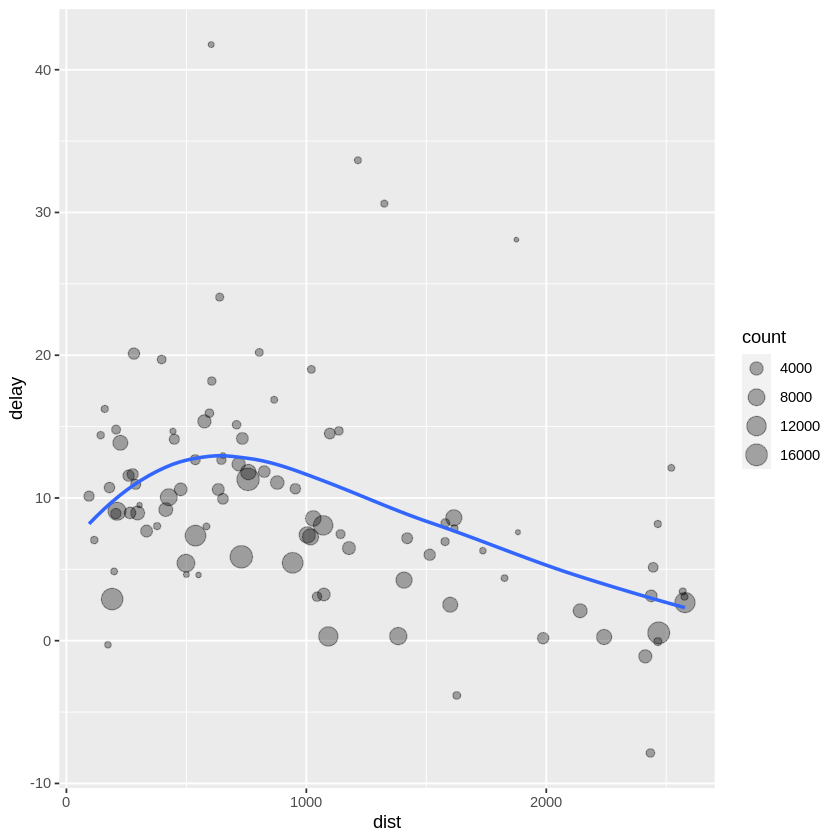

In [ ]:
ggplot(data = delay, mapping = aes(x = dist, y = delay)) +
  geom_point(aes(size = count), alpha = 1/3) +
  geom_smooth(se = FALSE)

It looks like delays increase with distance up to ~750 miles and then decrease. Maybe as flights get longer there's more ability to make up delays in the air?

Bovenstaande code kunnen we ook zonder de ' tussenvariabele' (by_dest) maken door een 'pipe' (%>%) te gebruiken:

`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


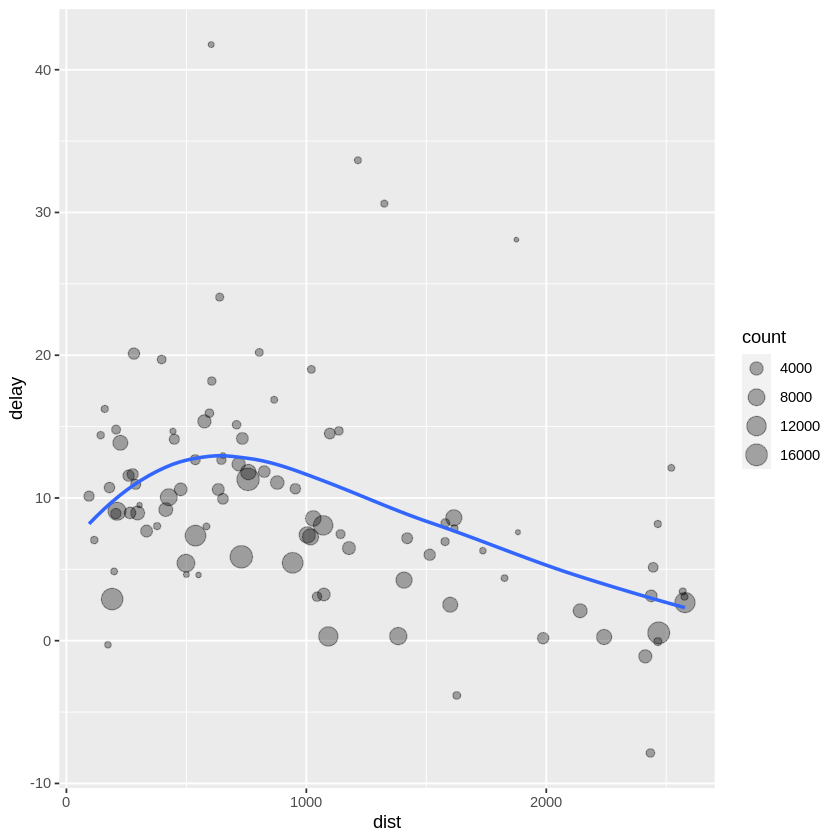

In [ ]:
delays <- nycflights13::flights %>%
  group_by(dest) %>%
  summarise(
    count = n(),
    dist = mean(distance, na.rm = TRUE),
    delay = mean(arr_delay, na.rm = TRUE)
  ) %>%
  filter(count > 20, dest != "HNL")
ggplot(data = delay, mapping = aes(x = dist, y = delay)) +
  geom_point(aes(size = count), alpha = 1/3) +
  geom_smooth(se = FALSE)

# Huiswerk

Laten we eens wat oefenen:<br>
- Maak een ' scatterplot' van de gemiddelde vertraging bij aankomst per vlucht.<br>
- Maak een overzicht van de gemiddelde vertraging bij aankomst per dag.<br>
- Maak een overzicht van de standaardafwijking van de 'distance' (= afstand in miles) per bestemming.<br>Sorteer in ' descending order' = grootste eerst.<br>
- Maak een overzicht dat per dag in 2013 de eerste en de laatste vertrokken vlucht laat zien.<br>
- Maak een telling van het aantal unieke maatschappijen dat naar een bestemming vliegt. Sorteer in 'descending order'.<br>
- Maak een overzicht dat per vliegmaatschappij laat zien naar hoeveel bestemmingen deze maatschappij vliegt. Sorteer alfabetisch.<br>
- Maak een top tien van vliegtuigen (gebruik tailnum) die het meest gevlogen hebben in 2013.<br>
- Maak een overzicht dat per dag laat zien hoeveel vluchten er voor 5 uur 's ochtends zijn vertrokken.<br>
- Maak een berekening van het % vluchten per dag met meer dan 1 uur vertraging.




En nog wat oefeningen die horen bij paragraaf 5.7:<br>
- Vind de populairste bestemming.<br>
- Welk vliegtuignummer (tailnum) heeft gemiddeld de meeste vertraging?<br>
- Op welk tijdstip op de dag is de kans op vertraging het grootst? Op welk het kleinst?
- Wat is de beste vliegmaatschappij = de maatschappij met de minste vertraging?